# L10 · NB 02 — Attention, intuitively

> ⏱️ **~25 min** core (Sections 1–8) · +25 min for the 🟡 Extension · one small model (`all-MiniLM-L6-v2`, ~90 MB — the same one from L09) — runs on any laptop

> *We've used transformers as black boxes for two lessons. Time to open one up. The single mechanism that makes everything work is **attention**. The core of this notebook needs **no maths** — just a few everyday sentences, starting with one about a trophy and a suitcase.*

By the end of this notebook you will:

1. Be able to explain attention in plain English — "each word looks around the sentence and decides who to listen to"
2. Understand what queries, keys, and values are *for* — a question, a name tag, and an info card
3. Be able to read an attention heatmap, and see why models use several attention "heads" at once
4. Be ready to USE pretrained transformers in NB 03 without it feeling like magic

> 🧮 **Curious about the maths?** The matrix version of attention lives in **Extension E1** at the end. It's optional — nothing later in the course depends on it.

---

### Where you are in L10

Marcus asked for a shopping assistant. Sarah can't build it in one leap — she works through four notebooks, each answering the next question in the chain:

| Step | Notebook | Sarah's question |
|---|---|---|
| 1 | `01_morning_briefing` | What can pretrained transformers already do, out of the box? |
| 2 | `02_attention_intuition` 👈 **you are here** | *Why* do they work? What is this "attention" everyone talks about? |
| 3 | `03_using_an_llm` | How do I drive a generative LLM myself — tokens, sampling, chat? |
| 4 | `04_rag_pipeline` | How do I ground it in NorthStar's catalogue? → the shopping assistant |

Right now you're on **step 2 of 4**. Each notebook stands on the one before it — run them in order.

## 1 · Setup


> **Why this cell first.**
> No big models here — just one small model in Section 3, loaded there. The setup just imports our plotting tools and **fixes the random seeds** (`torch.manual_seed(0)`, `np.random.seed(0)`), so the transformer block in Section 6 (and the optional maths in the Extension) gives the same numbers every time you run it.

In [18]:
# numpy for simple arithmetic, torch for the transformer block later,
# matplotlib + seaborn for bar charts and heatmaps.
import logging
# Silence harmless torch notice "Redirects are currently not supported in MacOs" (must run before torch is imported)
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(0)      # same random numbers every run
np.random.seed(0)

# Our running example — the first 6 words of the classic trophy/suitcase sentence.
# We'll use these 6 for the heatmaps (a small grid is easier to read).
TOKENS = ['the', 'trophy', "didn't", 'fit', 'because', 'it']
print(f"Sequence: {TOKENS}")

Sequence: ['the', 'trophy', "didn't", 'fit', 'because', 'it']


## 2 · What is attention? (the ELI5 version)

Read these two sentences:

> The trophy didn't fit in the suitcase because **it** was too **big**.
>
> The trophy didn't fit in the suitcase because **it** was too **small**.

You know instantly: in the first, *it* = the **trophy**. In the second, *it* = the **suitcase**. How? Without thinking about it, you glanced back at the other words and asked *"which one makes sense here?"* — something too big can't go *in*; something too small can't *hold*.

**That glance back is attention.** A transformer does exactly this, for every word, at the same time.

### The classroom analogy

Imagine every word in the sentence is a student in a classroom.

- 🙋 **"it" raises its hand and asks a question:** *"I'm something that's too big — who am I?"* → that question is the **query (Q)**
- 🏷️ **Every other word wears a name tag** describing itself: *trophy — "I'm an object"*, *suitcase — "I'm a container"*, *the — "I'm just a filler word"* → those name tags are the **keys (K)**
- 👀 **"it" looks around the room** and checks how well each name tag matches its question. Good match → listen closely. Poor match → mostly ignore. → those are the **attention weights**
- 📇 **Every word also holds an info card** with what it actually means. "it" copies notes from the cards — lots from the best match, a little from the rest. → those cards are the **values (V)**

After this, "it" is no longer a vague word. It now *carries the meaning* of "trophy" (or "suitcase").

| Piece | In the classroom | In plain English |
|---|---|---|
| **Query** | the question you ask | "what am I looking for?" |
| **Key** | the name tag you wear | "here's what I am" |
| **Value** | the info card you hold | "here's what I'll share" |
| **Attention weights** | how closely you listen to each classmate | percentages that add up to 100% |

> 💡 **Nobody writes these questions and name tags by hand.** The model *learns* them by reading billions of sentences. Our job today is just to understand what it's doing.

## 3 · Watch a real model decide

Enough storytelling — let's look inside an actual trained transformer and see who **it** listens to.

We'll use **`all-MiniLM-L6-v2`** — the same small model you used for embeddings in L09. It has 6 layers × 12 heads, and it learned its attention patterns by reading over a billion sentence pairs. Nobody typed any of the numbers you're about to see.

What the next cell does, in plain English:

1. Feed a sentence into the model and ask it to **report its attention** as well as its answer
2. Look at the **last layer** (where the model has had the most time to "think"), and **average its 12 heads** — so we're not cherry-picking one lucky head
3. Pull out the row for one word — e.g. **"it"** — and draw it as a bar chart: *how much is "it" listening to each other word?*

> **Two bits of housekeeping.** The model adds two invisible marker tokens, `[CLS]` at the start and `[SEP]` at the end, and real models park a lot of spare attention on them (a "nothing important here" default). We also hide the word listening to *itself*. We drop those three and re-scale the rest to 100%, so the bars show only the real words.

In [19]:
# Load a small pretrained transformer (~90 MB, downloads once, then cached).
# attn_implementation="eager" makes the model hand back its attention weights.
from transformers import AutoTokenizer, AutoModel

MODEL_NAME = 'sentence-transformers/all-MiniLM-L6-v2'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME, attn_implementation='eager').eval()


def get_attention(sentence, word, layer=-1):
    """Return (tokens, % of attention) that `word` pays to every other token, in one layer, averaged over heads."""
    enc = tokenizer(sentence, return_tensors='pt')
    tokens = tokenizer.convert_ids_to_tokens(enc.input_ids[0])
    assert word in tokens, f'"{word}" is not a single token here — the model sees: {tokens}'
    with torch.no_grad():
        attentions = model(**enc, output_attentions=True).attentions   # one (1, heads, n, n) tensor per layer
    i = tokens.index(word)
    row = attentions[layer][0].mean(dim=0)[i].clone()   # average the heads, keep the row for `word`
    row[0] = row[-1] = row[i] = 0                         # hide [CLS], [SEP] and the word itself
    pct = (row / row.sum() * 100).numpy()                 # re-scale the rest to 100%
    return tokens[1:-1], pct[1:-1]


def show_attention(sentence, word='it'):
    """Draw who `word` listens to in the model's last layer, as a bar chart."""
    tokens, pct = get_attention(sentence, word)
    colours = ['tab:green' if p == pct.max() else 'lightgray' for p in pct]   # highlight the winner
    fig, ax = plt.subplots(figsize=(10, 3))
    bars = ax.bar(range(len(tokens)), pct, color=colours)
    ax.set_xticks(range(len(tokens)), tokens, rotation=30)
    ax.bar_label(bars, fmt='%.0f%%', fontsize=9)
    ax.set_ylabel('% of attention')
    ax.set_ylim(0, 60)
    ax.set_title(f'Who does "{word}" listen to?  (real model: {MODEL_NAME.split("/")[-1]}, last layer)')
    plt.tight_layout()
    plt.show()


print(f'Loaded {MODEL_NAME}: {model.config.num_hidden_layers} layers × {model.config.num_attention_heads} heads')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loaded sentence-transformers/all-MiniLM-L6-v2: 6 layers × 12 heads


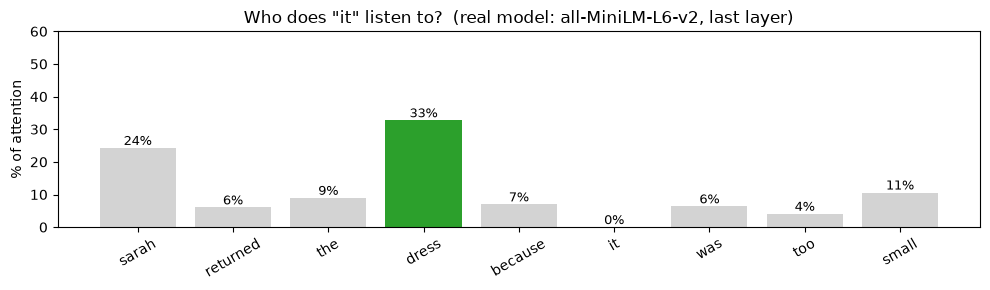

In [20]:
# Sarah is reading a customer review. What is "it"?
show_attention("sarah returned the dress because it was too small", word='it')

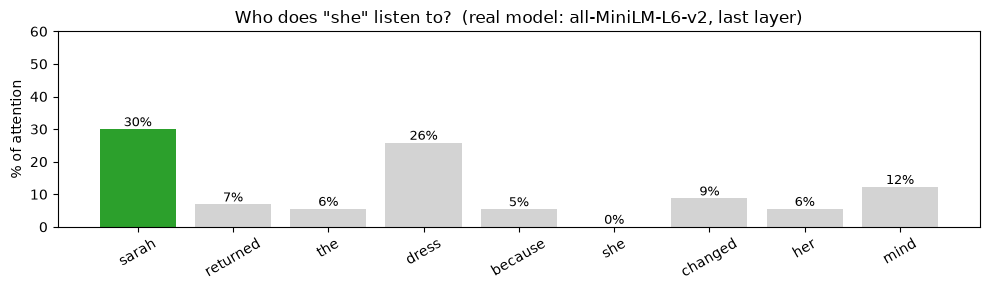

In [21]:
# Same opening words — but now the pronoun is "she". Who should she listen to?
show_attention("sarah returned the dress because she changed her mind", word='she')

**Same opening words, different pronoun — and the real model's attention flips.** "it" listens most to **dress** (a thing that can be too small); "she" listens most to **sarah** (a person who can change her mind). Nobody told the model that "it" means objects and "she" means people — it picked that up from reading.

Three things to notice about **real** attention, compared with the tidy story in Section 2:

- **The winner wins, but not by a landslide.** You'll see ~30%, not 90%. Each word keeps listening a bit to everything — the runner-up (*sarah* for "it", *dress* for "she") still gets a decent share.
- **Filler words get very little.** *the*, *because*, *was* sit near the bottom. Part of what a model learns is **what to ignore**.
- **This is one layer, averaged over 12 heads.** The model's full understanding is spread across all 6 layers and 72 heads — the bar chart is a peek, not the whole picture.

### ✏️ Your turn

1. Run the cell below — does "it" listen to the **cat** or the **road**?
2. Change *tired* to *wide* and run again. A road can be wide; a cat can't. Does the model notice?
3. Try a sentence of your own — e.g. `"the customer returned the jacket because it was torn"`. Keep it lowercase, and pass the pronoun you want to inspect as `word=`.

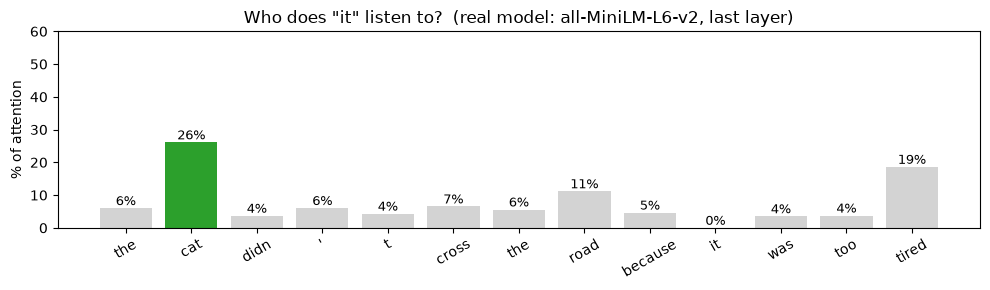

In [22]:
show_attention("the cat didn't cross the road because it was too tired", word='it')   # <-- edit the sentence

**What happened with "wide"?** When we tested it, the model *still* listened mostly to **cat** — it didn't flip to *road*. That's a real blind spot: a small model leans on simple habits (e.g. "it" usually means the first noun) rather than common sense about cats and roads.

This is exactly why the **trophy / suitcase** pair from Section 2 is famous: it's a classic test of AI reasoning (the *Winograd* challenge), and small models like this one fail it. Bigger models get it right much more often — which is a big part of why the industry keeps scaling up (Section 7).

### Bonus: watch the answer form, layer by layer

Each layer re-reads the sentence using what the previous layer worked out. Below, each **row** is one of the 6 layers, showing who "it" listens to at that depth.

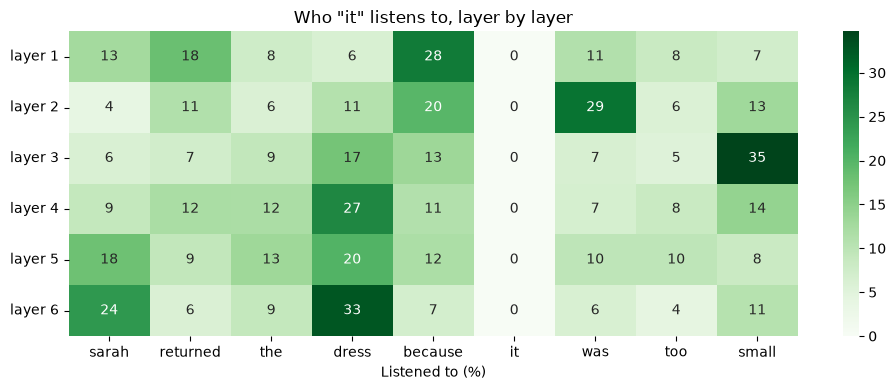

In [23]:
# One row per layer: who does "it" listen to at each depth of the model?
sentence = "sarah returned the dress because it was too small"
rows = []
for layer in range(model.config.num_hidden_layers):
    tokens, pct = get_attention(sentence, 'it', layer=layer)
    rows.append(pct)

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(np.array(rows), annot=True, fmt='.0f', cmap='Greens',
            xticklabels=tokens, yticklabels=[f'layer {l + 1}' for l in range(len(rows))], ax=ax)
ax.set_xlabel('Listened to (%)')
ax.tick_params(axis='y', rotation=0)
ax.set_title('Who "it" listens to, layer by layer')
plt.tight_layout()
plt.show()

Read it top to bottom. In the **early layers**, "it" mostly glances at its **neighbours** (*because*, *was*, *small*) — working out the local grammar. By the **later layers**, it has settled on **dress**. The model doesn't jump to the answer in one step; it builds it up, layer by layer — which is why transformers stack many blocks (Section 6).

## 4 · The whole room at once — reading an attention heatmap

So far we only looked at what one word (**"it"** or **"she"**) pays attention to. But in a transformer, **every word asks its own question at the same time**: *"fit"* asks "what is failing to fit?", *"didn't"* asks "which action am I negating?", and so on.

If we stack every word's bar chart on top of each other, we get a grid called an **attention heatmap**:

- **Each row** = one word asking its question (a bar chart like the ones in Section 3, turned sideways)
- **Each column** = a word being listened to
- **Darker cell** = more attention. Each row adds up to 1 (= 100%)

Below is an **idealised** heatmap for our 6-word sentence — numbers typed in by hand so the pattern is easy to read. As you saw in Section 3, real ones are messier: same idea, smaller margins.

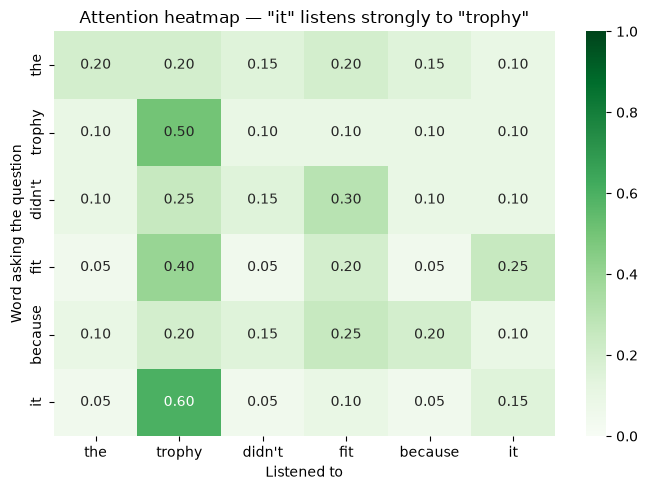

In [24]:
# A hand-typed attention grid — what a trained attention head might learn for this sentence.
# Each row is one word's "bar chart" as fractions (0.60 = 60%), and each row sums to 1.
hand_attn = torch.tensor([
    # the    trophy didn't  fit    because it     <-- listened TO
    [0.20,   0.20,  0.15,   0.20,  0.15,   0.10],   # the
    [0.10,   0.50,  0.10,   0.10,  0.10,   0.10],   # trophy listens mostly to itself
    [0.10,   0.25,  0.15,   0.30,  0.10,   0.10],   # didn't listens to the verb it negates
    [0.05,   0.40,  0.05,   0.20,  0.05,   0.25],   # fit listens to what is (not) fitting
    [0.10,   0.20,  0.15,   0.25,  0.20,   0.10],   # because listens broadly
    [0.05,   0.60,  0.05,   0.10,  0.05,   0.15],   # it listens strongly to trophy!
])

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(hand_attn.numpy(), annot=True, fmt='.2f', cmap='Greens',
            xticklabels=TOKENS, yticklabels=TOKENS, vmin=0, vmax=1, ax=ax)
ax.set_xlabel('Listened to')
ax.set_ylabel('Word asking the question')
ax.set_title('Attention heatmap — "it" listens strongly to "trophy"')
plt.tight_layout()
plt.show()

Look at the bottom row. The word **"it"** puts 0.60 (60%) of its attention on **"trophy"** — the same kind of picture as the bar charts in Section 3, just drawn as a row of coloured squares. That's how the model works out that *it* = *trophy*: when it builds its new understanding of "it", most of the notes it copies come from "trophy".

When you see attention heatmaps in articles or research papers, this is all they are: **who is listening to whom**.

## 5 · Multi-head attention — several questions at once

One question isn't enough to understand a sentence. "it" might want to know **who am I?** *and* **what action am I part of?** — two different questions with two different answers.

So transformers run several attentions side by side, called **heads**. Think of a team of detectives reading the same sentence, each hunting for a different kind of clue: one tracks *who's who*, another tracks *who did what*, another tracks *what describes what*. Each head produces its own heatmap.

Below are two **illustrative** heads with hand-typed numbers, so the contrast is easy to see. (The real bar charts in Section 3 were the *average* of 12 such heads.)

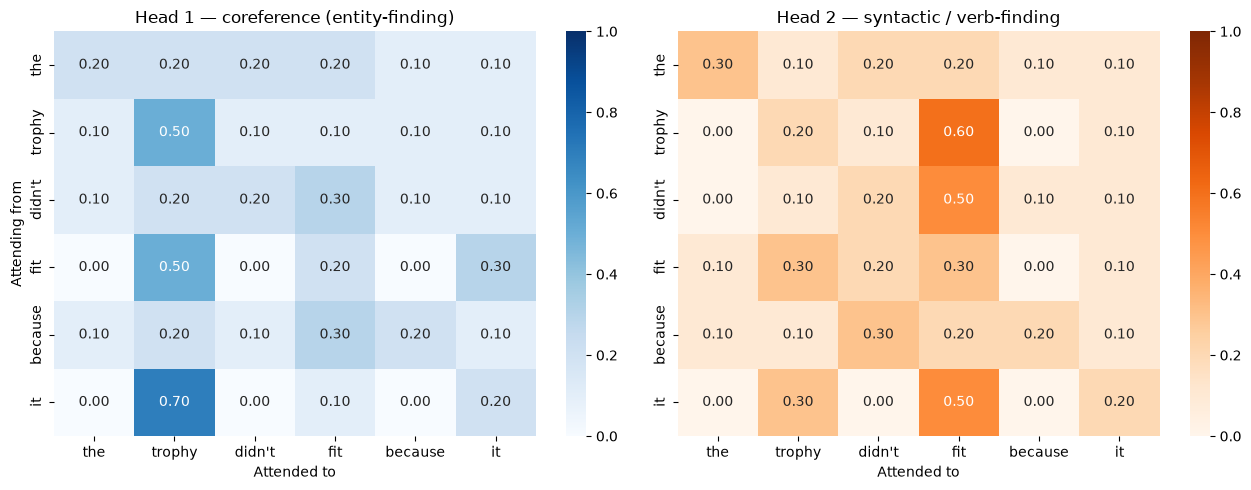

In [25]:
# Demonstrate two attention heads with different focus patterns.
# Each head is its own (6x6) attention matrix — same sentence, different relationship learned.
head_1 = torch.tensor([
    # 'it' focuses on entities
    [0.2, 0.2, 0.2, 0.2, 0.1, 0.1],
    [0.1, 0.5, 0.1, 0.1, 0.1, 0.1],
    [0.1, 0.2, 0.2, 0.3, 0.1, 0.1],
    [0.0, 0.5, 0.0, 0.2, 0.0, 0.3],
    [0.1, 0.2, 0.1, 0.3, 0.2, 0.1],
    [0.0, 0.7, 0.0, 0.1, 0.0, 0.2],   # 'it' -> 'trophy' (coreference head)
])
head_2 = torch.tensor([
    # focuses on syntax / verb structure
    [0.3, 0.1, 0.2, 0.2, 0.1, 0.1],
    [0.0, 0.2, 0.1, 0.6, 0.0, 0.1],   # 'trophy' attends to verb 'fit'
    [0.0, 0.1, 0.2, 0.5, 0.1, 0.1],
    [0.1, 0.3, 0.2, 0.3, 0.0, 0.1],
    [0.1, 0.1, 0.3, 0.2, 0.2, 0.1],
    [0.0, 0.3, 0.0, 0.5, 0.0, 0.2],   # 'it' attends to verb (different from head 1)
])

# Plot both heads side by side to see they capture different relationships from the same input.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(head_1.numpy(), annot=True, fmt='.2f', cmap='Blues',
            xticklabels=TOKENS, yticklabels=TOKENS, vmin=0, vmax=1, ax=axes[0])
axes[0].set_title('Head 1 — coreference (entity-finding)')
axes[0].set_xlabel('Attended to'); axes[0].set_ylabel('Attending from')

sns.heatmap(head_2.numpy(), annot=True, fmt='.2f', cmap='Oranges',
            xticklabels=TOKENS, yticklabels=TOKENS, vmin=0, vmax=1, ax=axes[1])
axes[1].set_title('Head 2 — syntactic / verb-finding')
axes[1].set_xlabel('Attended to')

plt.tight_layout()
plt.show()

**Two heads, two completely different patterns.** In Head 1 (the "who's who" detective), "it" listens to "trophy". In Head 2 (the "who did what" detective), "it" listens to "fit". Both clues are useful; combining them is what gives a transformer its rich understanding of each word.

In a real model: typically 12–16 heads per layer (GPT-3 uses 96) × 12–96 layers. Nobody assigns the heads their jobs — each one picks up its speciality during training. Some end up tracking grammar, some meaning, some long-range connections.

## 6 · The transformer block — putting it together

So far we've seen **attention** in a real model and in illustrated heatmaps: a way for each token to look at every other token and pull in a weighted mix of their information. That's the heart of a transformer — but it's not the *whole* thing.

A real transformer wraps attention in a small, repeating package called a **transformer block**. Think of attention as the engine, and the block as the car built around it. Every block does the same steps, in order:

```
                  ┌──────────────────────────────────────────────┐
   input x ──────►│  1. Multi-head Attention   (tokens mix info)  │
                  │  2. Add + LayerNorm   (x + attention) ◄─────── residual
                  │  3. Feed-forward      (think about each token)│
                  │  4. Add + LayerNorm   (x + feed-forward) ◄──── residual
                  └──────────────────────────────────────────────┘
                                    │
                                    ▼  output (same shape as input)
```

Attention you already understand. The new pieces are each simple — here's the intuition for *why* they exist:

**Feed-forward** — a tiny 2-layer neural network applied to each token *on its own* (no mixing between tokens). Attention gathers information from other tokens; the feed-forward layer then *thinks about* what was gathered. Rough analogy: attention is "listen to the room," feed-forward is "now process what you heard."

**Residual connection** (`x + f(x)`) — instead of *replacing* a token's vector, we *add* the new information on top of the original. The token keeps its identity and gains a bit more. This is the single trick that lets us stack dozens of blocks without the signal getting scrambled — the original always has a clean path straight through.

**LayerNorm** — after adding, the numbers can drift to very large or very small ranges, which makes training unstable. LayerNorm rescales each token's vector back to a tidy range (mean 0, variance 1). Housekeeping that keeps the math well-behaved.

> **The key idea:** a "transformer model" is nothing more than this one block, **stacked many times**. Because the output has the exact same shape as the input, block 2 can eat block 1's output, block 3 eats block 2's, and so on — 12 times for BERT-base, 96 for GPT-3. Same recipe, repeated.

Now let's build one and count its parts.

In [26]:
# Sketch a transformer block in PyTorch — this is essentially what's inside BERT, GPT, Llama
class TransformerBlock(nn.Module):
    def __init__(self, d_model=64, n_heads=4, d_ff=256):
        super().__init__()
        # Multi-head attention: runs n_heads attentions in parallel over d_model-wide vectors.
        # batch_first=True means inputs are shaped (batch, seq_len, d_model).
        self.attn = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
        # Feed-forward: expand to d_ff, apply ReLU non-linearity, project back to d_model.
        # Acts on each token independently, adding transformation capacity.
        self.ff = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, d_model),
        )
        # LayerNorm normalises each token vector (mean 0, var 1) to stabilise training.
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x):
        # Self-attention sublayer with residual + layer norm
        # attn(x, x, x): query=key=value=x, so every token attends to every token (self-attention).
        attn_out, _ = self.attn(x, x, x)
        # x + attn_out is the residual connection: keep the original x, add what attention learned.
        x = self.norm1(x + attn_out)
        # Feed-forward sublayer with residual + layer norm (same residual pattern)
        x = self.norm2(x + self.ff(x))
        return x

block = TransformerBlock(d_model=64, n_heads=4)
# Count every learnable parameter (weights + biases) across all sublayers.
n_params = sum(p.numel() for p in block.parameters())
print(f"One transformer block: {n_params:,} parameters")

# Forward pass on a fake batch of size 1, sequence length 6, dim 64
fake = torch.randn(1, 6, 64)
out = block(fake)
print(f"Input shape : {fake.shape}")
# Output keeps the (batch, seq_len, d_model) shape -> blocks can be stacked indefinitely.
print(f"Output shape: {out.shape}  (same shape — same as input)")

One transformer block: 49,984 parameters
Input shape : torch.Size([1, 6, 64])
Output shape: torch.Size([1, 6, 64])  (same shape — same as input)


**Read the output above carefully — two things matter:**

1. **The parameter count (~50K).** These are the numbers the model *learns* during training — including the machinery that writes each word's question, name tag and info card (Q, K, V), and the feed-forward weights. Right now they're random. Training is the process of nudging all ~50K of them until the attention patterns become useful (like the 'it → dress' pattern you read out of the real model in Section 3).

2. **Input shape == output shape** — `(1, 6, 64)` in, `(1, 6, 64)` out. This is the property that makes stacking possible. The block transformed the *contents* of each token vector but not its *shape*, so we can feed the output straight into an identical block. Deep transformers are just this, over and over.

**~50K parameters in one block** at d_model=64. Real transformers use d_model=768 (BERT-base) up to 12,288 (GPT-3). Stack 12-96 of these. That's it. Same recipe, different scale.

## 7 · Scaling: the same recipe from MiniLM to GPT-4

| Model | Params | Layers | Heads | d_model | Training data |
|-------|--------|--------|-------|---------|---------------|
| `all-MiniLM-L6-v2` (L09, Section 3 above) | 22M | 6 | 12 | 384 | 1B+ sentence pairs |
| BERT-base | 110M | 12 | 12 | 768 | English Wikipedia + BookCorpus (~3.3B tokens) |
| GPT-2 medium | 355M | 24 | 16 | 1024 | WebText (~40GB) |
| GPT-3 | 175B | 96 | 96 | 12,288 | Internet + books + code |
| GPT-4 | ~1T (est.) | unknown | unknown | unknown | unknown |

*(Specs as publicly reported — frontier models change fast, so treat the last rows as a snapshot circa 2025, not gospel.)*

**Every entry uses the same architecture.** The Lego brick is identical. What changes:

- The **size** of the bricks (d_model, n_heads)
- The **stack height** (number of layers)
- The **training data** (more data, more diverse data, code, conversation)
- The **post-training** (instruction tuning, RLHF for the chat models)

That's the entire story of GenAI architecture in 6 lines. Everything else is engineering, data, and money.

## 8 · Recap

You've now seen attention four ways:

1. **In plain English** — each word asks a question (**query**), checks every other word's name tag (**key**), and copies notes from the best matches' info cards (**value**)
2. **In a real model** — bar charts read straight out of `all-MiniLM-L6-v2`, showing "it" → *dress* and "she" → *sarah*, plus the model's blind spots
3. **Visually** — heatmaps showing who listens to whom, with several heads each hunting for a different clue
4. **Architecturally** — wrapped in a transformer block with residuals, layer norm, and feed-forward layers, then stacked many times

**The one-sentence version:** *attention lets every word look at every other word and decide which ones matter for its meaning.*

**Next:** in NB 03 we'll load a small *generative* transformer (SmolLM2-360M) and have it write text. Same architecture as above. Same Lego bricks. Just trained for a different objective.

---

## 🟡 Extension — self-study after class

*Skipping this section will not affect your understanding of later lessons. Come back to it when you have time and want to go deeper.*

## E1 · Under the hood — the attention maths

In Section 3 we read attention straight out of a real model. Here's how the model *computes* it. Every step maps onto the classroom:

| Classroom | Maths |
|---|---|
| Each word writes a question, a name tag, an info card | Multiply each word's vector by three learned matrices → **Q**, **K**, **V** |
| "How well does this name tag match my question?" | **Dot product** of each query with each key (`Q @ K.T`) |
| Turn match scores into percentages | Divide by √d, then **softmax** (each row sums to 1) |
| Copy notes, mostly from the best matches | **Weighted sum** of the values (`weights @ V`) |

First, each word needs a vector (a list of numbers) to start from. We hand-craft tiny 4-number vectors so that "it" sits halfway between "trophy" (an entity) and "fit" (a verb) — it's ambiguous until attention resolves it.

In [27]:
# Each token is represented by a 4-dimensional embedding (in real models, 768+)
D = 4  # embedding dimension (the "width" of each token vector)

# Hand-crafted embeddings — each row is one token's embedding (shape: 6 tokens x 4 dims)
X = torch.tensor([
    [0.1, 0.0, 0.0, 0.0],   # the         (function word, low signal)
    [0.0, 1.0, 0.0, 0.0],   # trophy      (entity dim = 1)
    [0.0, 0.0, 0.1, 0.0],   # didn't      (function word)
    [0.0, 0.0, 0.0, 1.0],   # fit         (verb dim = 1)
    [0.1, 0.0, 0.0, 0.0],   # because     (function word)
    [0.0, 0.5, 0.0, 0.5],   # it          (ambiguous — half-entity, half-verb)
])
# X.shape is (seq_len, D) = (6, 4): one 4-dim row vector per token
print(f"Embeddings shape: {X.shape}  ({len(TOKENS)} tokens × {D} dims)")

Embeddings shape: torch.Size([6, 4])  (6 tokens × 4 dims)


Now the four steps, using **random** (untrained) Q/K/V matrices:

1. Project each token to a **query** (Q), **key** (K), and **value** (V) vector
2. Compute similarity scores between every query and every key (dot product)
3. Scale by √d and apply softmax → these are the attention weights
4. Each output token = weighted sum of values, using the attention weights

In [28]:
# Initialise random Q/K/V projection matrices, each (D, D) = (4, 4).
# These are the only learnable params of attention; here they're random (untrained).
# The *0.5 just keeps the random values small so scores don't explode.
W_q = torch.randn(D, D) * 0.5  # turns an embedding into a "query"  (what am I looking for?)
W_k = torch.randn(D, D) * 0.5  # turns an embedding into a "key"    (what do I offer?)
W_v = torch.randn(D, D) * 0.5  # turns an embedding into a "value"  (what info do I pass on?)

# Step 1: project to Q, K, V.
# X is (6, 4) and each W is (4, 4), so X @ W is (6, 4): every token gets its own Q, K, V vector.
Q = X @ W_q
K = X @ W_k
V = X @ W_v
print(f"Q shape: {Q.shape}")
print(f"K shape: {K.shape}")
print(f"V shape: {V.shape}")

Q shape: torch.Size([6, 4])
K shape: torch.Size([6, 4])
V shape: torch.Size([6, 4])


In [29]:
# Step 2: similarity scores via dot products between every query and every key.
# Q is (6, 4), K.T is (4, 6), so Q @ K.T is (6, 6): scores[i, j] = how much token i's
# query matches token j's key. Higher dot product = more relevant.
scores = Q @ K.T
print(f"Raw scores (Q · Kᵀ):  shape {scores.shape}")
print(scores.numpy())

Raw scores (Q · Kᵀ):  shape torch.Size([6, 6])
[[ 1.2262302e-02 -1.7495330e-02  3.9007282e-03  8.9223385e-03
   1.2262302e-02 -4.2864955e-03]
 [ 5.2913919e-02  5.2940822e-01 -9.8636031e-02  3.2066274e-01
   5.2913919e-02  4.2503554e-01]
 [ 6.5608468e-04 -5.1814687e-02  9.2511885e-03 -2.4880644e-02
   6.5608468e-04 -3.8347665e-02]
 [-2.3049316e-03 -8.8480020e-01  1.1916099e-01 -2.5146171e-01
  -2.3049316e-03 -5.6813097e-01]
 [ 1.2262302e-02 -1.7495330e-02  3.9007282e-03  8.9223385e-03
   1.2262302e-02 -4.2864955e-03]
 [ 2.5304493e-02 -1.7769599e-01  1.0262476e-02  3.4600522e-02
   2.5304493e-02 -7.1547732e-02]]


In [30]:
# Step 3: scale by sqrt(d), then softmax across each row.
# Dividing by sqrt(D) keeps the scores from growing with dimension, which would push
# softmax into tiny gradients. softmax(dim=-1) turns each ROW into positive numbers that
# sum to 1 -> a probability distribution over "which tokens to attend to".
attn_weights = F.softmax(scores / (D ** 0.5), dim=-1)
print(f"Attention weights (each row sums to 1):")
print(attn_weights.numpy().round(3))

Attention weights (each row sums to 1):
[[0.167 0.165 0.167 0.167 0.167 0.166]
 [0.153 0.194 0.142 0.175 0.153 0.184]
 [0.168 0.164 0.169 0.166 0.168 0.165]
 [0.187 0.12  0.199 0.165 0.187 0.141]
 [0.167 0.165 0.167 0.167 0.167 0.166]
 [0.171 0.154 0.17  0.172 0.171 0.163]]


In [31]:
# Step 4: each output token = weighted sum of all value vectors, using the attention weights.
# attn_weights is (6, 6), V is (6, 4), so the product is (6, 4): output row i blends every
# token's V together, weighted by how much token i attends to each. Same shape as input X.
output = attn_weights @ V
print(f"Output shape: {output.shape}  (same as input — one new vector per token)")
print(output.numpy().round(3))

Output shape: torch.Size([6, 4])  (same as input — one new vector per token)
[[-0.042  0.098 -0.051  0.013]
 [-0.055  0.104 -0.048  0.016]
 [-0.042  0.097 -0.05   0.012]
 [-0.021  0.095 -0.06   0.016]
 [-0.042  0.098 -0.051  0.013]
 [-0.037  0.101 -0.055  0.018]]


**That's the whole operation.** Four matrix ops. Every other token's V is averaged in, weighted by how relevant it is to this token's query.

Each row of `attn_weights` is one token's attention — the same kind of heatmap as Section 4, but now computed rather than typed in (with random, untrained matrices).

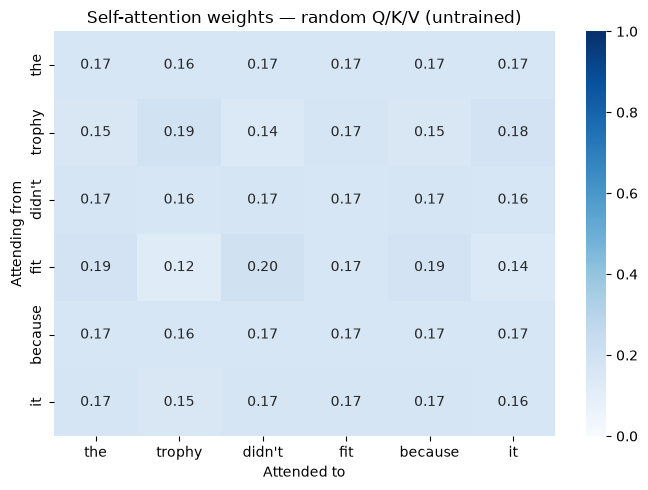

In [32]:
# Visualise attn_weights (6x6) as a heatmap. Row = token attending FROM, column = attended TO.
# Brighter cell = more attention. With random weights the pattern is near-uniform / meaningless.
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(attn_weights.numpy(), annot=True, fmt='.2f', cmap='Blues',
            xticklabels=TOKENS, yticklabels=TOKENS, vmin=0, vmax=1, ax=ax)
ax.set_xlabel('Attended to')
ax.set_ylabel('Attending from')
ax.set_title('Self-attention weights — random Q/K/V (untrained)')
plt.tight_layout()
plt.show()

With **random** weights the attention pattern is random — there's no learned structure yet. In a trained transformer, you'd see something different — like the real model in Section 3, where 'it' leaned towards 'dress' and 'she' towards 'sarah'. (And as Section 3 showed, even trained small models don't reliably solve the trophy/suitcase riddle.)

That's the trained pattern attention is supposed to learn. We're seeing the architecture; training data does the rest.

## E2 · Causal (masked) attention

The attention we built is **bidirectional** — token 1 can attend to token 6, and vice versa. That's what BERT and embedding models use.

GPT-family models are **autoregressive** — they generate one token at a time, and each token can only attend to PREVIOUS tokens (otherwise the model would cheat during training by looking at the answer). In classroom terms: each student may only ask classmates who spoke *before* them. This is implemented with a triangular *causal mask*.

*(Uses `scores` from E1 — run E1 first.)*

Causal mask:
[[  0. -inf -inf -inf -inf -inf]
 [  0.   0. -inf -inf -inf -inf]
 [  0.   0.   0. -inf -inf -inf]
 [  0.   0.   0.   0. -inf -inf]
 [  0.   0.   0.   0.   0. -inf]
 [  0.   0.   0.   0.   0.   0.]]


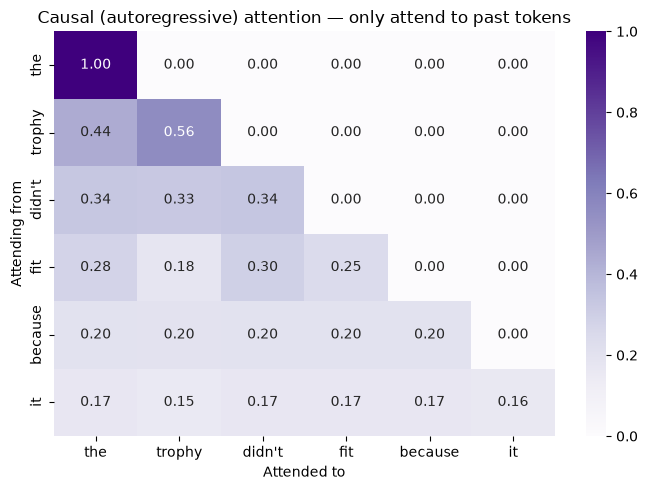

In [33]:
# Causal mask — upper triangle (future tokens) set to -inf.
# triu(..., diagonal=1) keeps everything strictly ABOVE the diagonal; those become -inf,
# the rest stay 0. Shape (6, 6).
mask = torch.triu(torch.full((6, 6), float('-inf')), diagonal=1)
print("Causal mask:")
print(mask.numpy())

# Apply to our scores and re-softmax.
# Adding -inf to "future" cells means softmax turns them into exactly 0 (e^-inf = 0),
# so each token can only attend to itself and earlier tokens — never the future.
masked_scores = scores + mask
causal_attn = F.softmax(masked_scores / (D ** 0.5), dim=-1)

# Heatmap shows a lower-triangular pattern: row i has weight only on columns <= i.
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(causal_attn.numpy(), annot=True, fmt='.2f', cmap='Purples',
            xticklabels=TOKENS, yticklabels=TOKENS, vmin=0, vmax=1, ax=ax)
ax.set_title('Causal (autoregressive) attention — only attend to past tokens')
ax.set_xlabel('Attended to')
ax.set_ylabel('Attending from')
plt.tight_layout()
plt.show()

See the lower-triangular pattern? Each row sums to 1, but the upper-triangular cells are 0. Token 3 attends to tokens 0, 1, 2, 3 — but not 4 or 5 (the future).

This single change is what makes GPT generative. The architecture is otherwise identical to BERT. Same Lego brick, different mask.

## E3 · Attention complexity

Attention computes pairwise scores between every pair of tokens. For a sequence of length N, that's O(N²) operations and O(N²) memory.

For N=512 (typical BERT max length), that's 262K pairs per layer — fine.
For N=8,192 (long-context model), that's 67M pairs per layer — expensive.
For N=128,000 (Claude / GPT-4 long context), that's 16 *billion* pairs per layer.

This is why long-context LLMs are slower and more expensive. Recent research (Flash Attention, sliding window, Mamba) tries to bring the cost down — but vanilla attention is still O(N²).

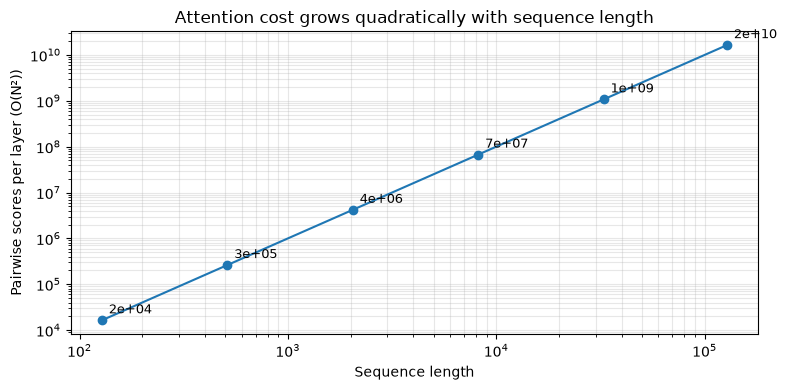

In [34]:
# Visualise attention cost growth
import math
# A range of sequence lengths from short (128) to huge long-context (128k tokens).
seq_lens = [128, 512, 2048, 8192, 32768, 128000]
# Attention compares every token with every other -> N*N pairwise scores per layer (O(N^2)).
costs = [n**2 for n in seq_lens]

# Log-log plot: a straight line confirms the quadratic (power-law) growth in cost.
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(seq_lens, costs, marker='o')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Sequence length')
ax.set_ylabel('Pairwise scores per layer (O(N²))')
ax.set_title('Attention cost grows quadratically with sequence length')
ax.grid(alpha=0.3, which='both')
# Annotate each point with its pairwise-score count in scientific notation.
for n, c in zip(seq_lens, costs):
    ax.annotate(f'{c:,.0e}', (n, c), textcoords='offset points', xytext=(5, 5), fontsize=9)
plt.tight_layout()
plt.show()

**Practical implication:** when a customer asks 'can you process this 200-page document?', the answer involves serious cost arithmetic. Long context isn't free.